# Imports

In [2]:
import subprocess
import os
import glob
import sys
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import linecache
from tqdm import tqdm

# Scan s-bend waveguide in wavelength

In [3]:
device_name = "SbendWaveguide"
working_dir = f"C:\\Users\\runner\\ActivePIC\\{device_name}\\"
save_dir = f"{device_name}_scan_Wav"
filename = f"{device_name}.ind"
wav_arr = np.linspace(1.45, 1.65, 51)
# wav_arr = [278, 308, 338]

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    # Set wavelength in .ind file
    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.write(working_dir+filename)
    
    # Define the command and arguments
    wav_str = f"{wav:0.3f}".replace(".", "p")
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{save_dir}{wav_str}", "wait=0"]

    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

100%|██████████████████████████████████████████████████████████████████████████████████| 51/51 [33:45<00:00, 39.72s/it]


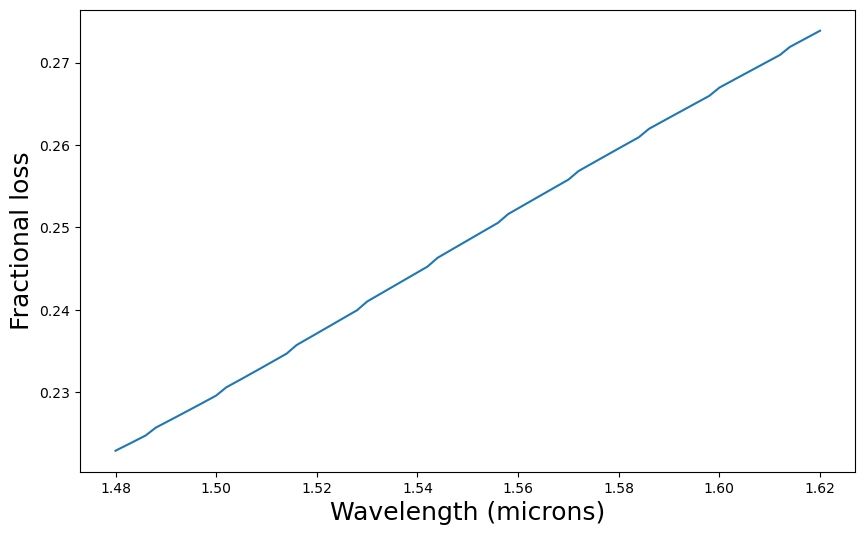

In [30]:
working_dir = f"C:\\Users\\runner\\ActivePIC\\{device_name}\\"
save_dir = f"{device_name}_scan_Wav"
fontsize = 18

filenames_mon = glob.glob(working_dir+save_dir+"\*[0-9].mon")
wav, power = [], []

for filename in filenames_mon:
    data = np.genfromtxt(filename, delimiter='', skip_header=5)
    wav.append(float(filename.split('Wav')[-1].split('.')[0].replace('p', '.')))
    power.append(data[-1, 1])
wav, power = np.array(wav), np.array(power)

# Plot loss
fig, ax = plt.subplots(1, 1, figsize=(10,6))
plt.plot(wav, 1 - power)
plt.xlabel('Wavelength (microns)', fontsize=fontsize)
plt.ylabel('Fractional loss', fontsize=fontsize)
plt.show()